Testing for Mallows

In [1]:
!jupyter nbconvert --to script req_functions_from_ApproxSP.ipynb


usage: jupyter [-h] [--version] [--config-dir] [--data-dir] [--runtime-dir]
               [--paths] [--json] [--debug]
               [subcommand]

Jupyter: Interactive Computing

positional arguments:
  subcommand     the subcommand to launch

options:
  -h, --help     show this help message and exit
  --version      show the versions of core jupyter packages and exit
  --config-dir   show Jupyter config dir
  --data-dir     show Jupyter data dir
  --runtime-dir  show Jupyter runtime dir
  --paths        show all Jupyter paths. Add --json for machine-readable
                 format.
  --json         output paths as machine-readable json
  --debug        output debug information about paths

Available subcommands: kernel kernelspec migrate run troubleshoot

Jupyter command `jupyter-nbconvert` not found.


In [18]:
from req_functions_from_ApproxSP import *
import random
import math
from tqdm import tqdm
from generate_profiles import *
from euclidean import *

number = []
n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (500):
            cnt=0
            pref=mallows_prefs_two(n, phi1, phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                result = self_manipulation(mpref, wpref, manipulator)
                if result [0]!= matching:
                    cnt = cnt+1
            count.append(cnt)
        #number_phi.append(sum(count) / len(count))
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
        else:
            number_phi.append(0)
    number.append(number_phi)
print(number)

100%|███████████████████████████████████████████████████████████████████████████████████| 6/6 [44:40<00:00, 446.79s/it]

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.894, 1.04, 0.838, 0.34, 0.186], [0.0, 1.058, 1.496, 1.442, 0.868, 0.444], [0.0, 0.672, 1.304, 1.664, 1.51, 0.768], [0.0, 0.33, 0.754, 1.332, 1.902, 2.258], [0.0, 0.11, 0.262, 0.624, 1.418, 2.638]]


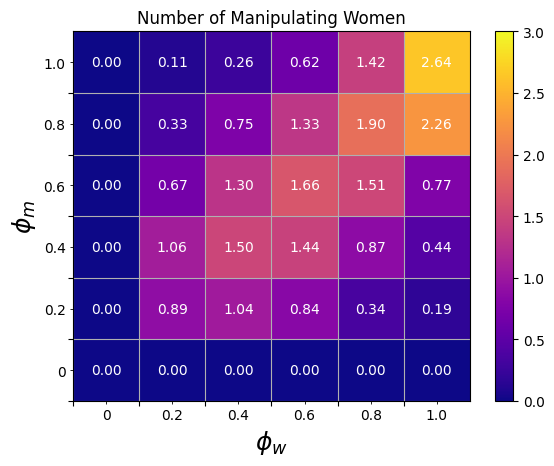

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(number)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=3))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Number of Manipulating Women')
plt.grid(True)

plt.savefig("number_of_manipulators_Mallows", format='pdf')
plt.show()

Testing for Euclidean

In [1]:
!pip install mapel

In [10]:
from euclidean import *
import random
import math
from tqdm import tqdm
#from ApproximateSP import *
from generate_profiles import *
from mapel import *
from numpy import linalg
from mapel.marriages.cultures.mallows import mallows_votes

In [15]:
pref = generate_euclidean_votes(5, 2)
print(pref)

[[0.90993777 0.23103781]
 [0.37299128 0.56619534]
 [0.90104989 0.43328738]
 [0.67488309 0.24474165]
 [0.0824279  0.59000555]] [[0.51767953 0.13451404]
 [0.88711579 0.31420971]
 [0.67545635 0.14253163]
 [0.76399421 0.52659867]
 [0.50171655 0.19160612]]
[[[2, 3, 4, 1, 5], [4, 5, 1, 3, 2], [2, 4, 3, 5, 1], [3, 5, 1, 2, 4], [5, 1, 4, 3, 2]], [[4, 1, 2, 3, 5], [1, 3, 4, 2, 5], [4, 1, 3, 2, 5], [3, 4, 1, 2, 5], [4, 2, 1, 3, 5]]]


In [15]:
#Euclidean; no manipulation!

from req_functions_from_ApproxSP import *
import random
import math
from tqdm import tqdm
from generate_profiles import *
from euclidean import *

number_euclidean = []
n=30
dim = [1, 2, 5, 10]

for d in tqdm(dim):
    count = []
    ct = []
    for samples in range(500):
        cnt = 0
        pref = generate_euclidean_votes(n, d)
        #print(pref)
        mpref = pref[0]
        wpref = pref[1]
        matching = gale_shapley(mpref, wpref)
        for manipulator in range (1, n+1):
            result = self_manipulation(mpref, wpref, manipulator)
            #print(matching, result[0])
            if result[0] != matching:
                cnt += 1
        count.append(cnt)
        #print(count)
    if len(count) > 0:
        number_euclidean.append(sum(count)/len(count))
    else:
        number_euclidean.append(0)
#number_euclidean.append(number_phi)
print(number_euclidean)

100%|██████████| 4/4 [00:18<00:00,  4.71s/it]

[0.0, 0.0, 0.0, 0.0]


In [6]:
#Euclidean Mallows for d=2

from req_functions_from_ApproxSP import *
import random
import math
from tqdm import tqdm
from generate_profiles import *
from euclidean import *

number = []
n=30
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (500):
            cnt=0
            pref=generate_mallows_euclidean_votes(n, phi1, phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                result = self_manipulation(mpref, wpref, manipulator)
                if result [0]!= matching:
                    cnt = cnt+1
            count.append(cnt)
        #number_phi.append(sum(count) / len(count))
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
        else:
            number_phi.append(0)
    number.append(number_phi)
print(number)

100%|███████████████████████████████████████████████████████████████████████████████████| 6/6 [13:12<00:00, 132.09s/it]

[[0.0, 0.18, 0.594, 0.88, 1.486, 2.552], [0.172, 0.378, 0.74, 1.11, 1.528, 2.488], [0.582, 0.722, 0.898, 1.208, 1.556, 2.844], [0.904, 1.02, 1.296, 1.514, 1.932, 2.858], [1.592, 1.732, 1.696, 1.998, 2.296, 2.946], [2.416, 2.386, 2.442, 2.472, 2.378, 2.514]]


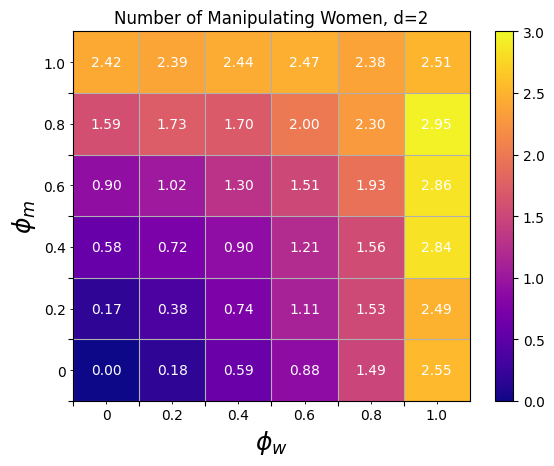

In [10]:
#Euclidean-Mallows for d=2

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(number)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=3))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Number of Manipulating Women, d=2')
plt.grid(True)

plt.savefig("number_of_manipulators_Euclidean_Mallows", format='pdf')
plt.show()

Testing for Reverse Euclidean

In [18]:
def get_uniform_point(dim: int) -> list:
    """Generate a random point uniformly in a dim-dimensional unit cube [0,1]^dim."""
    return [np.random.random() for _ in range(dim)]

def generate_reverse_euclidean_votes(num_agents: int = None,
                                     dim: int = None,
                                     space='uniform',
                                     phi=0.5,
                                    proportion: float = None,
                                     **kwargs):
    name = f'{dim}d_{space}'

    left = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right = np.array([get_uniform_point(dim) for _ in range(num_agents)])

    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            distances[v][c] = np.linalg.norm(left[v] - right[c])
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            distances[v][c] = np.linalg.norm(right[v] - left[c])
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    p = proportion
    for i in range(int(num_agents * (1. - p))):
        tmp = list(left_votes[i])
        tmp.reverse()
        left_votes[i] = tmp

        tmp = list(right_votes[i])
        tmp.reverse()
        right_votes[i] = tmp

    left_votes_lst = left_votes.tolist()
    right_votes_lst = right_votes.tolist()

    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [19]:
#Reverse Euclidean

from ApproximateSP import *
import random
import math
from tqdm import tqdm
from generate_profiles import *
#from euclidean import *

number_reverse_euclidean = []

n=30
p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
for d in tqdm(d_list):
    number_d = []
    for p in tqdm(p_list):
        count = []
        ct = []
        for samples in range(500):
            cnt = 0
            pref = generate_reverse_euclidean_votes(n, d, 'uniform',
                                     0.5, p)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                result = self_manipulation(mpref, wpref, manipulator)
                if result[0] != matching:
                    cnt += 1
            count.append(cnt)
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
        else:
            number_d.append(0)
    number_reverse_euclidean.append(number_d)
print(number_reverse_euclidean)

100%|██████████| 10/10 [05:45<00:00, 34.60s/it]

[[0.0, 0.528, 0.81, 0.944, 0.462, 0.0], [0.0, 0.748, 1.252, 1.134, 0.682, 0.0], [0.0, 1.004, 1.282, 1.262, 0.758, 0.0], [0.0, 0.912, 1.334, 1.31, 0.768, 0.0], [0.0, 0.942, 1.35, 1.452, 0.756, 0.0], [0.0, 0.968, 1.39, 1.418, 0.788, 0.0], [0.0, 0.868, 1.392, 1.31, 0.888, 0.0], [0.0, 0.98, 1.49, 1.418, 0.836, 0.0], [0.0, 0.922, 1.416, 1.202, 0.802, 0.0], [0.0, 0.93, 1.42, 1.414, 0.908, 0.0]]


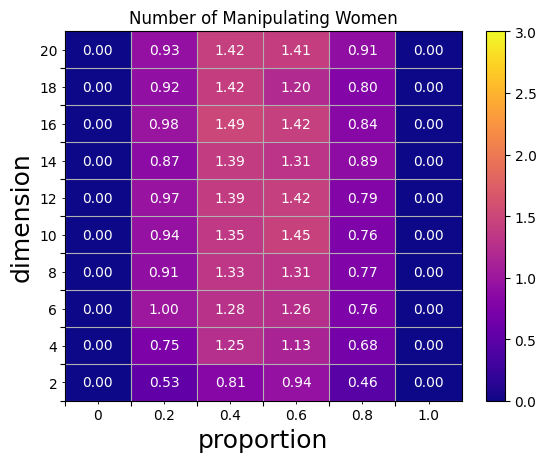

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
    
w_number = np.array(number_reverse_euclidean)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=3))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(p_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('proportion', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Number of Manipulating Women')
plt.grid(True)

plt.savefig("number_of_manipulators_reverse_euclidean.pdf", format='pdf')
plt.show()

Testing Expectations Euclidean

In [2]:
from ApproximateSP import *
from tqdm import tqdm
from generate_profiles import *
%load_ext autoreload
%autoreload 2
import euclidean



100%|██████████| 6/6 [17:52<00:00, 178.76s/it]


[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.938, 1.096, 0.824, 0.346, 0.144], [0.0, 1.064, 1.444, 1.438, 0.858, 0.342], [0.0, 0.676, 1.224, 1.742, 1.256, 0.796], [0.0, 0.402, 0.85, 1.32, 1.956, 2.102], [0.0, 0.132, 0.366, 0.762, 1.514, 2.428]]
euclidean for n=5:  [[[3, 4, 1, 5, 2], [4, 1, 3, 5, 2], [2, 5, 3, 4, 1], [5, 2, 4, 3, 1], [4, 1, 5, 3, 2]], [[2, 1, 5, 3, 4], [3, 4, 1, 2, 5], [1, 3, 2, 5, 4], [2, 1, 5, 3, 4], [4, 3, 2, 5, 1]]]


In [21]:
import numpy as np

def generate_expectation_votes(num_agents: int = None,
                               dim: int = None,
                               space='uniform',
                               std: float = None,
                               phi=0.5,
                               **kwargs):
    name = f'{dim}d_{space}'

    left_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    left_agents_wishes = np.zeros([num_agents, dim])

    right_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right_agents_wishes = np.zeros([num_agents, dim])

    for v in range(num_agents):
        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        left_agents_wishes[v][0] = np.random.normal(left_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        left_agents_wishes[v][1] = np.random.normal(left_agents_reality[v][1], std)

        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        right_agents_wishes[v][0] = np.random.normal(right_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        right_agents_wishes[v][1] = np.random.normal(right_agents_reality[v][1], std)

    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            distances[v][c] = np.linalg.norm(right_agents_reality[c] - left_agents_wishes[v])
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            distances[v][c] = np.linalg.norm(left_agents_reality[c] - right_agents_wishes[v])
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    left_votes_lst = [list(row) for row in left_votes]
    right_votes_lst = [list(row) for row in right_votes]


    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [22]:

number_expectations_euclidean = []

n = 30
std_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]

for d in tqdm(d_list):
    number_d = []
    for std in tqdm(std_list):
        count = []
        ct = []
        for samples in range(500):
            cnt = 0
            pref = generate_expectation_votes(n, d, 'uniform', std, 0.5)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                result = self_manipulation(mpref, wpref, manipulator)
                if result[0] != matching:
                    cnt += 1
            count.append(cnt)
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
        else:
            number_d.append(0)
    number_expectations_euclidean.append(number_d)
print(number_expectations_euclidean)

100%|██████████| 10/10 [51:47<00:00, 310.77s/it]

[[0.0, 2.44, 2.334, 1.916, 1.786, 1.728], [0.0, 0.706, 1.17, 1.366, 1.666, 1.56], [0.0, 0.546, 1.098, 1.196, 1.348, 1.44], [0.0, 0.622, 0.926, 1.224, 1.398, 1.406], [0.0, 0.462, 1.124, 1.202, 1.244, 1.502], [0.0, 0.418, 0.95, 1.21, 1.394, 1.244], [0.0, 0.422, 0.95, 1.13, 1.186, 1.294], [0.0, 0.396, 0.938, 1.082, 1.338, 1.282], [0.0, 0.34, 0.922, 1.168, 1.234, 1.294], [0.0, 0.418, 0.95, 1.162, 1.142, 1.368]]


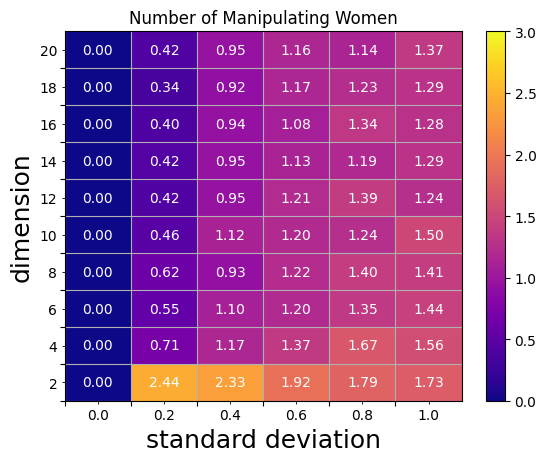

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

std_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
    
w_number = np.array(number_expectations_euclidean)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=3))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(std_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('standard deviation', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Number of Manipulating Women')
plt.grid(True)

plt.savefig("number_of_manipulators_expectations_euclidean.pdf", format='pdf')
plt.show()

Testing Fame Euclidean

In [24]:
def generate_fame_votes(num_agents: int = None,
                        dim: int = None,
                        space='uniform',
                        radius: float = None,
                        **kwargs):

    name = f'{dim}d_{space}'

    left = np.array([get_rand(name, i=i, num_agents=num_agents) for i in range(num_agents)])
    right = np.array([get_rand(name, i=i, num_agents=num_agents) for i in range(num_agents)])

    left_rays = np.array([np.random.uniform(0, radius) for _ in range(num_agents)])
    right_rays = np.array([np.random.uniform(0, radius) for _ in range(num_agents)])

    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            distances[v][c] = np.linalg.norm(left[v] - right[c])
            distances[v][c] = distances[v][c] - right_rays[c]
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            distances[v][c] = np.linalg.norm(right[v] - left[c])
            distances[v][c] = distances[v][c] - left_rays[c]
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    left_votes_lst = left_votes.tolist()
    right_votes_lst = right_votes.tolist()

    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [25]:
number_fame_euclidean = []

d_list = [2, 3, 5, 10]
f_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
n = 30

for d in tqdm(d_list):
    number_d = []
    for f in tqdm(f_list):
        count = []
        ct = []
        for samples in range(500):
            cnt = 0
            pref = generate_fame_votes(n, d, 'uniform', f)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                result = self_manipulation(mpref, wpref, manipulator)
                if result[0] != matching:
                    cnt += 1
            count.append(cnt)
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
        else:
            number_d.append(0)
    number_fame_euclidean.append(number_d)
print(number_fame_euclidean)

100%|██████████| 4/4 [03:34<00:00, 53.54s/it]

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]]


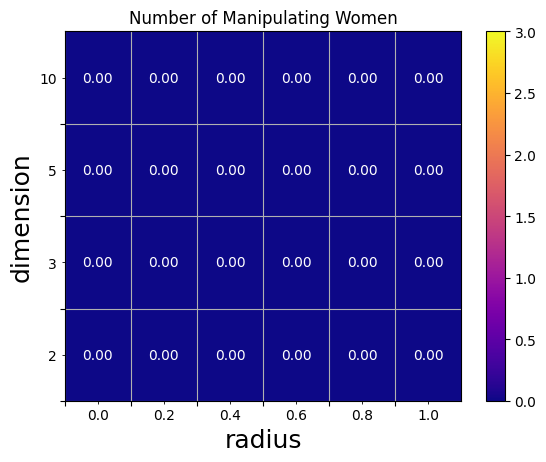

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

d_list = [2, 3, 5, 10]
f_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
    
w_number = np.array(number_fame_euclidean)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=3))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(f_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('radius', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Number of Manipulating Women')
plt.grid(True)

plt.savefig("number_of_manipulators_fame_euclidean", format='pdf')
plt.show()

Testing Attributes

In [9]:
import pandas as pd

def get_uniform_point(dim: int) -> list:
    """Generate a random point uniformly in a dim-dimensional unit cube [0,1]^dim."""
    return [np.random.random() for _ in range(dim)]

def weighted_l1(a1, a2, w):
    total = 0
    for i in range(len(a1)):
        total += abs(a1[i] - a2[i]) * w[i]
    return total

def generate_attributes_votes(num_agents: int = None,
                              dim: int = None,
                              space: str = 'uniform',
                              **kwargs):
    name = f'{dim}d_{space}'

    left_agents_skills = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    left_agents_weights = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right_agents_skills = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right_agents_weights = np.array([get_uniform_point(dim) for _ in range(num_agents)])

    votes = np.zeros([num_agents, num_agents], dtype=int)
    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)
    ones = np.ones([dim], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            if dim == 1:
                distances[v][c] = (1. - right_agents_skills[c]) * left_agents_weights[v]
            else:
                distances[v][c] = weighted_l1(ones, right_agents_skills[c], left_agents_weights[v])
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            if dim == 1:
                distances[v][c] = (1. - left_agents_skills[c]) * right_agents_weights[v]
            else:
                distances[v][c] = weighted_l1(ones, left_agents_skills[c], right_agents_weights[v])
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    left_votes_lst = left_votes.tolist()
    right_votes_lst = right_votes.tolist()

    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [13]:
pref = generate_attributes_votes(4, 2)

print(pref[0])


[[2, 3, 1, 4], [2, 1, 3, 4], [2, 1, 4, 3], [2, 1, 4, 3]]


In [10]:
from tqdm import tqdm
from req_functions_from_ApproxSP import *
import json
number_attributes = []
n=30
d_list = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]

number_d = []
data_attributes = []
for d in tqdm(d_list):
    count = []
    ct = []
    for samples in range(1000): #replace this to do 1000 samples
        cnt = 0
        pref = generate_attributes_votes(n, d)
        mpref = pref[0]
        wpref = pref[1]
        matching = gale_shapley(mpref, wpref)
        for manipulator in range (1, n+1):
            result = self_manipulation(mpref, wpref, manipulator)
            if result[0] != matching:
                cnt += 1
        count.append(cnt)
        data_attributes.append([d, json.dumps(mpref), json.dumps(wpref), samples, count])
    if len(count) > 0:
        number_d.append(count)
    else:
        number_d.append(0)
#number_attributes.append(number_d)
print(number_d)

100%|██████████| 10/10 [13:38<00:00, 81.89s/it]

[[0, 0, 0, 2, 4, 0, 0, 0, 0, 4, 0, 2, 0, 0, 4, 4, 2, 2, 8, 0, 0, 2, 4, 0, 0, 0, 0, 3, 0, 0, 2, 2, 0, 0, 1, 6, 3, 0, 0, 2, 2, 0, 0, 0, 0, 2, 0, 0, 0, 2, 7, 2, 0, 3, 0, 0, 2, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 5, 0, 2, 0, 2, 0, 2, 0, 3, 2, 0, 2, 0, 3, 3, 0, 0, 3, 2, 0, 0, 0, 2, 0, 5, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 3, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 3, 2, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 3, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 3, 0, 0, 0, 3, 0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 2, 0, 2, 0, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 3, 0, 0, 2, 0, 3, 0, 0, 0, 0, 0, 0, 2, 6, 0, 0, 2, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 4, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 3, 0, 3, 2, 0, 0, 3, 2, 0, 0, 0, 0, 0, 0, 4, 2, 0, 0, 0, 0, 2, 0, 2, 0, 0, 2, 2, 3, 4, 0, 0, 0, 2, 0, 0, 2, 3, 2, 0, 0, 0, 0, 0, 4, 0, 0, 0, 2, 3, 4, 0, 2, 0, 0, 2, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2, 2, 0, 0, 4, 0, 0, 0, 4, 0, 2, 2, 0, 3, 2, 2, 0, 0, 0, 2, 0, 0, 2,

In [11]:
df2 = pd.DataFrame(data_attributes, columns=["dimension", "mpref", "wpref", "sample", "count"])
df2.to_csv('attributes.csv', index=False)

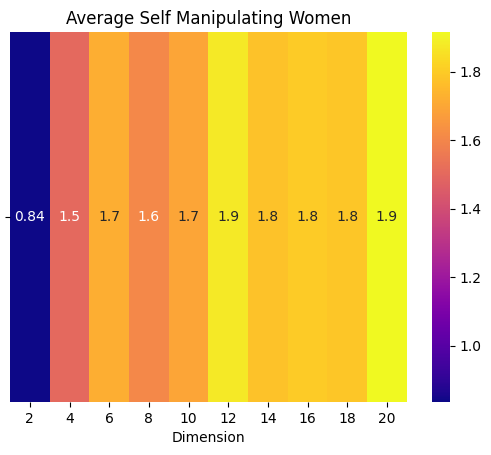

In [14]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

average_values = [np.mean(counts) for counts in number_d]

sns.heatmap([average_values], annot=True, xticklabels=d_list, yticklabels=[""], cmap = 'plasma')
plt.title("Average Self Manipulating Women")
plt.xlabel("Dimension")
plt.savefig("self_manip_attributes.pdf", format='pdf')
plt.show()

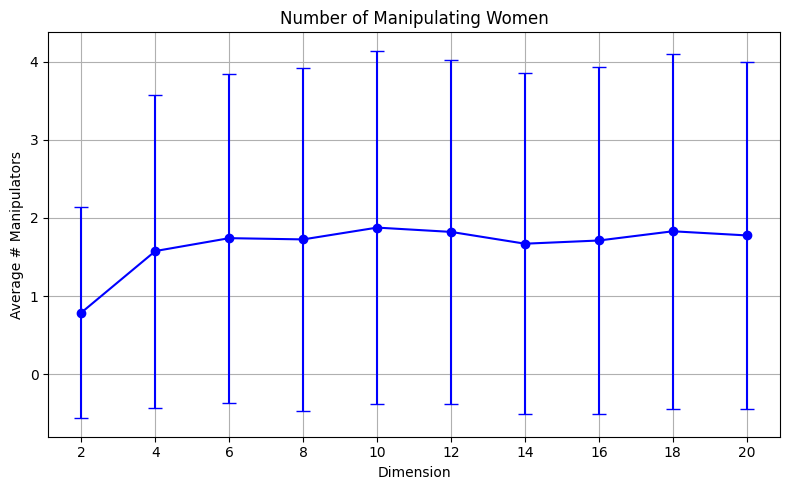

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming number_d contains a list of lists: 500 samples per dimension
# Example structure: number_d = [[cnt1, cnt2, ..., cnt500], [cnt1, ..., cnt500], ...]

d_list = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]

# Compute the average and standard deviation for each dimension
average_values = [np.mean(counts) for counts in number_d]
std_values = [np.std(counts) for counts in number_d]

# Plot with error bars
plt.figure(figsize=(8, 5))
plt.errorbar(d_list, average_values, yerr=std_values, fmt='o-', color='b', capsize=5)
plt.title('Number of Manipulating Women')
plt.xlabel('Dimension')
plt.ylabel('Average # Manipulators')
plt.xticks(d_list)
plt.grid(True)
plt.tight_layout()
plt.savefig("number_of_manipulators_attributes.pdf", format='pdf')
plt.show()

